# Assignment 1 — Data Cleaning & Exploratory Data Analysis (EDA)

**Dataset:** Titanic passenger dataset (891 rows, 15 columns). A classic public
dataset (originally from the UCI / Kaggle / OpenML repositories, also bundled with
seaborn) that is ideal for demonstrating a full cleaning + EDA workflow because it
contains **missing values, categorical variables, outliers, and correlated numeric
features**.

**Objective:** Perform data cleaning and EDA to gain insight into which passengers
survived.

**Workflow covered**
1. Handle missing values
2. Detect and treat outliers
3. Convert categorical data to numerical
4. Plot distributions
5. Analyze data using correlation
6. Feature selection
7. PCA (Principal Component Analysis)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
np.random.seed(42)

# Load the locally-cached dataset (reproducible, no internet needed)
df = pd.read_csv("../data/titanic.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 1. First look at the data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Handle missing values

We inspect the null counts, then decide a strategy per column:
- **age** — numeric, ~20% missing → impute with the median.
- **embarked / embark_town** — categorical, 2 missing → impute with the mode.
- **deck** — ~77% missing → too sparse to be useful, drop it.
- We also drop redundant columns (`alive` is a leak of `survived`, `class`/`who`
  duplicate `pclass`/`sex`+`age`).

In [4]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "pct": missing_pct}).sort_values("missing", ascending=False)

,missing,pct
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2
survived,0,0.0
pclass,0,0.0
sex,0,0.0
sibsp,0,0.0
parch,0,0.0
fare,0,0.0


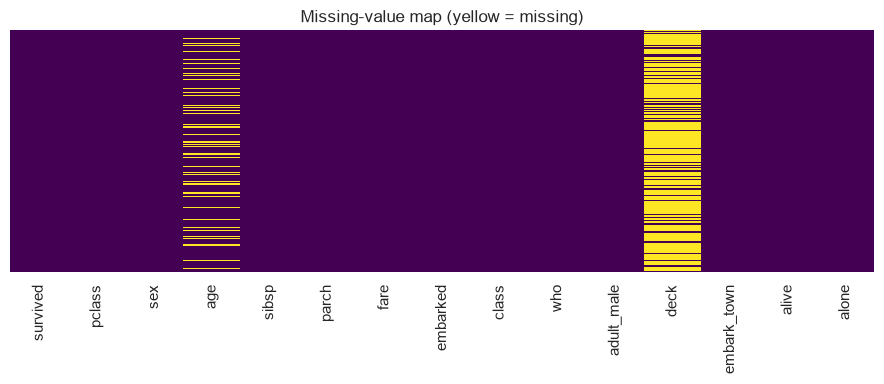

In [5]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing-value map (yellow = missing)")
plt.tight_layout(); plt.show()

In [6]:
df = df.drop(columns=["deck", "alive", "class", "who", "adult_male", "embark_town"])

df["age"] = df["age"].fillna(df["age"].median())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

print("Remaining missing values:", int(df.isna().sum().sum()))
df.head()

Remaining missing values: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


## 3. Detect and treat outliers

We use the IQR (inter-quartile range) rule on the two continuous features `age`
and `fare`. Values outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` are flagged. Rather than
dropping rows we **cap (winsorize)** them to the fence, which preserves sample size.

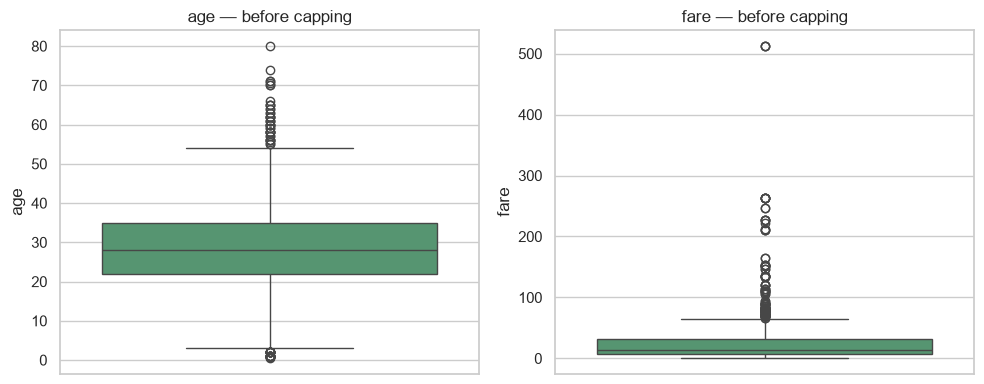

In [7]:
num_cols = ["age", "fare"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#4C9F70")
    ax.set_title(f"{c} — before capping")
plt.tight_layout(); plt.show()

In [8]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    n_out = ((df[c] < lo) | (df[c] > hi)).sum()
    df[c] = df[c].clip(lo, hi)
    print(f"{c:5s}: {n_out:3d} outliers capped to [{lo:.1f}, {hi:.1f}]")

age  :  66 outliers capped to [2.5, 54.5]
fare : 116 outliers capped to [-26.7, 65.6]


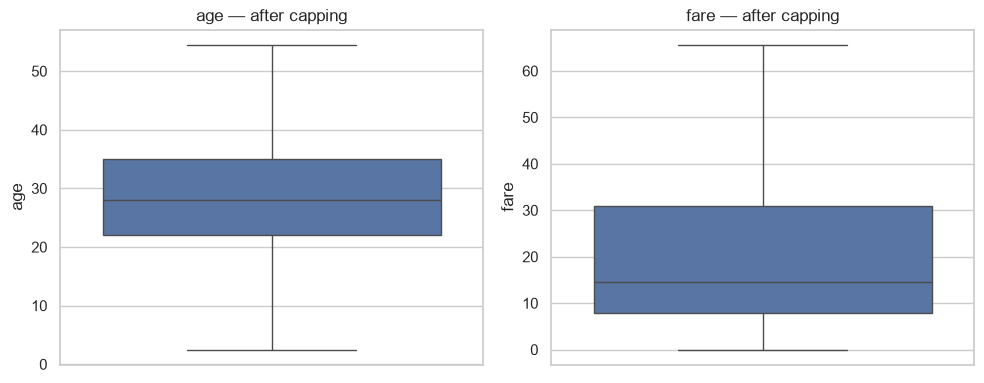

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#4C72B0")
    ax.set_title(f"{c} — after capping")
plt.tight_layout(); plt.show()

## 4. Convert categorical data to numerical

- **sex** and **alone** are binary → map to 0/1.
- **embarked** has 3 categories → one-hot encode (drop first to avoid
  the dummy-variable trap).

In [10]:
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df["alone"] = df["alone"].astype(int)
df = pd.get_dummies(df, columns=["embarked"], drop_first=True, dtype=int)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,alone,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,65.6344,0,0,0
2,1,3,1,26.0,0,0,7.9250,1,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,1,0,1


## 5. Plot distributions

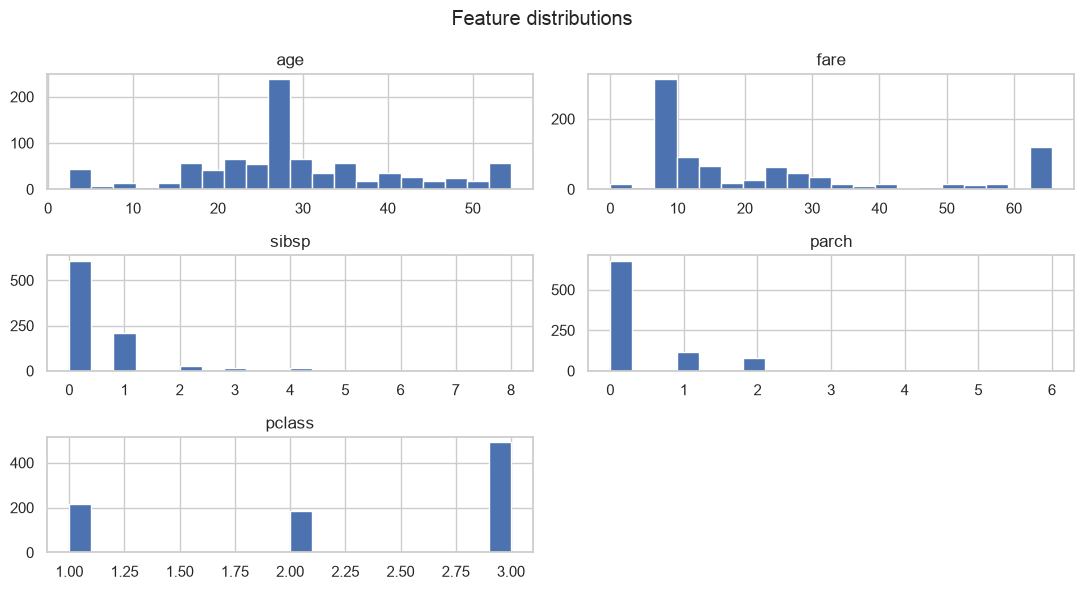

In [11]:
num_features = ["age", "fare", "sibsp", "parch", "pclass"]
df[num_features].hist(figsize=(11, 6), bins=20, color="#4C72B0", edgecolor="white")
plt.suptitle("Feature distributions")
plt.tight_layout(); plt.show()

/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_4027/2693260482.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="survived", ax=axes[0], palette="Set2")
/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_4027/2693260482.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="survived", y="age", ax=axes[1], palette="Set2")
/var/folders/tw/40g2wc7563q0c9v1b05m6wqm0000gn/T/ipykernel_4027/2693260482.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="pclass", y="survived", ax=axes[2], palett

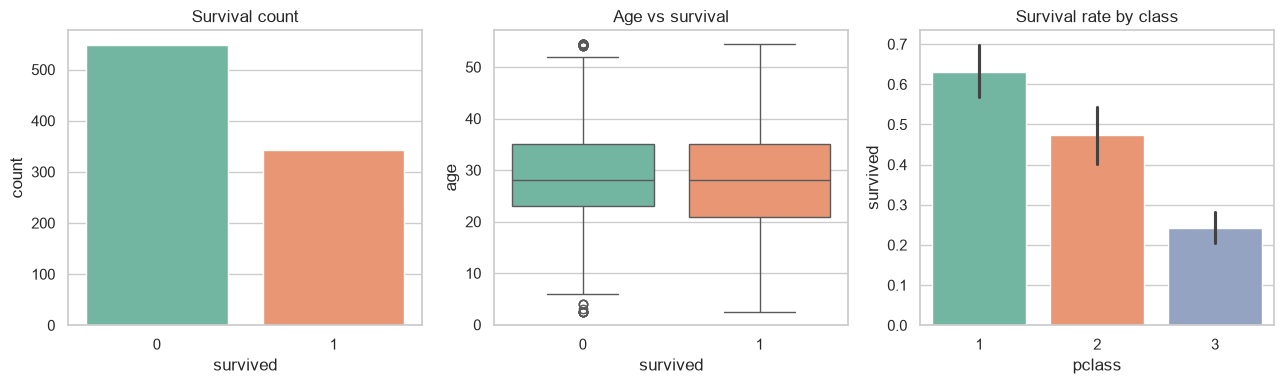

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.countplot(data=df, x="survived", ax=axes[0], palette="Set2")
axes[0].set_title("Survival count")
sns.boxplot(data=df, x="survived", y="age", ax=axes[1], palette="Set2")
axes[1].set_title("Age vs survival")
sns.barplot(data=df, x="pclass", y="survived", ax=axes[2], palette="Set2")
axes[2].set_title("Survival rate by class")
plt.tight_layout(); plt.show()

## 6. Correlation analysis

A correlation heatmap reveals linear relationships between features and the target
(`survived`), and multicollinearity between predictors.

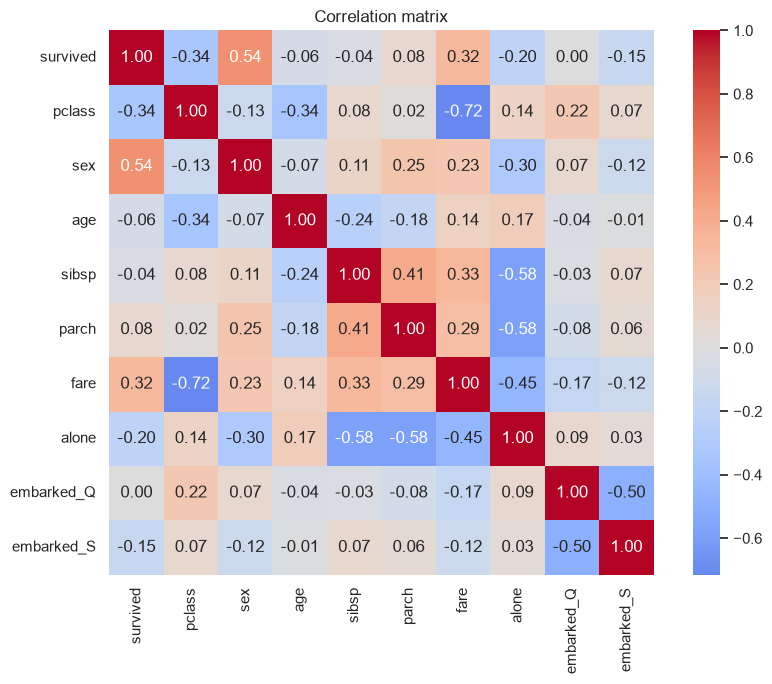

In [13]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

In [14]:
print("Correlation with target (survived):")
corr["survived"].drop("survived").sort_values(key=abs, ascending=False)

Correlation with target (survived):


sex           0.543351
pclass       -0.338481
fare          0.317430
alone        -0.203367
embarked_S   -0.149683
parch         0.081629
age          -0.060622
sibsp        -0.035322
embarked_Q    0.003650
Name: survived, dtype: float64

**Reading the matrix:** `sex` (+0.54) and `pclass` (-0.34) are the strongest
signals — women and higher-class passengers survived more. `fare` is positively
correlated with survival but also with `pclass`, hinting at redundancy.

## 7. Feature selection

We compare two complementary techniques:
- **Univariate** — `SelectKBest` with the ANOVA F-test ranks each feature's
  individual relationship with the target.
- **Model-based** — a Random Forest's `feature_importances_` captures non-linear
  and interaction effects.

In [15]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=["survived"])
y = df["survived"]

skb = SelectKBest(score_func=f_classif, k="all").fit(X, y)
anova = pd.Series(skb.scores_, index=X.columns).sort_values(ascending=False)

rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X, y)
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

ranks = pd.DataFrame({"ANOVA_F": anova, "RF_importance": rf_imp})
ranks

,ANOVA_F,RF_importance
age,3.279177,0.258643
alone,38.353651,0.014325
embarked_Q,0.011846,0.010576
embarked_S,20.374460,0.023231
fare,99.614870,0.254267
parch,5.963464,0.033424
pclass,115.031272,0.089744
sex,372.405724,0.272201
sibsp,1.110572,0.043588


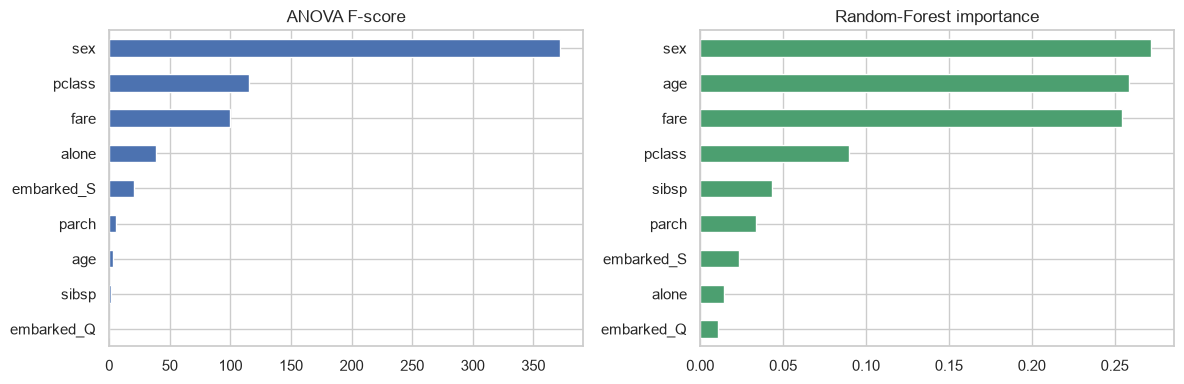

Top-5 features (RF): ['sex', 'age', 'fare', 'pclass', 'sibsp']


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
anova.plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("ANOVA F-score"); axes[0].invert_yaxis()
rf_imp.plot.barh(ax=axes[1], color="#4C9F70"); axes[1].set_title("Random-Forest importance"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

top = rf_imp.head(5).index.tolist()
print("Top-5 features (RF):", top)

## 8. PCA (Principal Component Analysis)

PCA requires standardized features. We project the data onto its principal
components, inspect the **explained-variance ratio** to decide how many components
retain ~90% of the information, and visualize the first two components.

Components needed for >=90% variance: 7 of 9


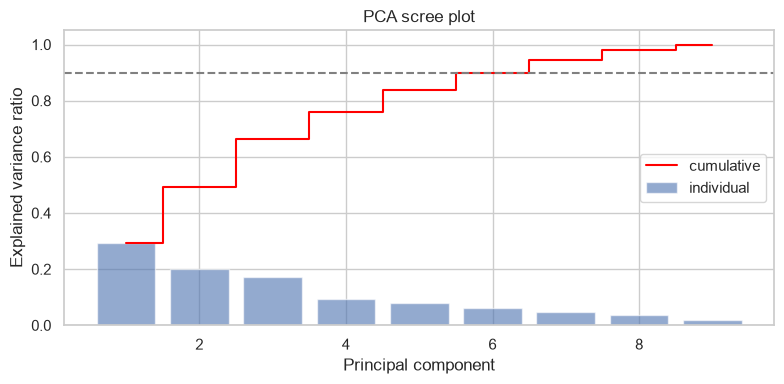

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n_90 = int(np.argmax(cum >= 0.90) + 1)
print(f"Components needed for >=90% variance: {n_90} of {X.shape[1]}")

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(evr) + 1), evr, alpha=0.6, label="individual")
plt.step(range(1, len(cum) + 1), cum, where="mid", color="red", label="cumulative")
plt.axhline(0.90, ls="--", color="gray")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot"); plt.legend(); plt.tight_layout(); plt.show()

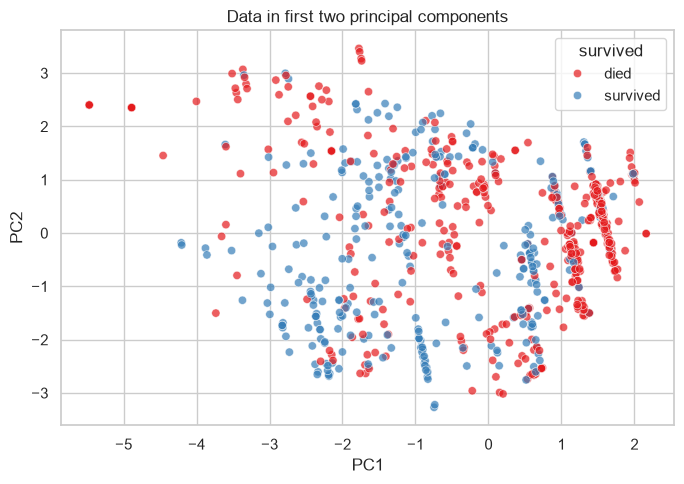

In [18]:
pcs = PCA(n_components=2).fit_transform(X_scaled)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=y.map({0: "died", 1: "survived"}),
                palette="Set1", alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Data in first two principal components")
plt.tight_layout(); plt.show()

## Conclusion

- Missing values were imputed (age → median, embarked → mode) and the sparse
  `deck` column dropped.
- Outliers in `age` and `fare` were capped using the IQR rule.
- Categorical variables were encoded numerically.
- **`sex`, `pclass`, `fare`, and `age`** are the most informative features for
  predicting survival — consistent across correlation, ANOVA, and Random-Forest.
- PCA shows the information can be compressed into a handful of components while
  retaining ~90% of the variance, and the survived/died groups are partly
  separable already in the first two components.
